# Paper figures

Builds every figure and table used in the paper from **saved** experiment outputs. No simulation runs here: rerun `run_mpc.ipynb` / `run_irf.ipynb` first, then run all cells. Outputs go to `data/output_data/paper-figures/`.

| # | Output | Files |
|---|---|---|
| 1 | Impact MPC by income, liquidity, borrowing, balance-sheet group, constraint | `paper_impact_mpc.*` |
| 2 | Aggregate MPC table and cumulative MPC chart | `paper_mpc_table.*`, `paper_cumulative_mpc.*` |
| 3 | MPC by the 8 balance-sheet groups; KVW robustness | `paper_mpc_by_group8.*`, `paper_mpc_by_kvw_class.csv` |
| 4 | IRFs: monetary policy, one-off transfer | `paper_irf_macro.*` |
| 5 | Transfer fiscal multiplier | `paper_transfer_multiplier.*` |

Excluded until fixed: income-tax IRF (payroll wedge), government consumption (rationing), income-uncertainty IRF (pending rerun with the +1% shock).

In [ ]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.household_classes import (
    GROUP_LABELS,
    HTM_CLASSES,
    classify_balance_sheet_groups,
    classify_households,
)
from src.mpc_paper_groups import prepare_paper_groups
from src.paper_plots import GROUP_SHORT, cumulative_mpc_figure, irf_figure, mpc_impact_figure, multiplier_figure
from src.paper_plots import STYLE as paper_style
from src.visual_helpers import _prepare_irf_plot_panel

MPC_DIR = Path("data/output_data/mpc-experiment/analysis")
# Which IRF run to use: "elb" (benchmark, zero floor) or "no_elb" (floor removed); see run_irf.ipynb.
IRF_REGIME = "no_elb"
# Choose the saved experiment explicitly; no simulations are launched here.
IRF_EXPERIMENT = "job_loss_designs"  # "job_loss_designs" or "legacy"
IRF_PREVENT_REHIRING = True  # For job_loss_designs: select restricted/unrestricted outputs.
IRF_REHIRING_SCOPE = "all_unemployed"  # "displaced" loads the earlier cohort-only experiment.
if IRF_EXPERIMENT not in {"job_loss_designs", "legacy"}:
    raise ValueError("IRF_EXPERIMENT must be job_loss_designs or legacy")
irf_run_name = "irf-experiment" + ("" if IRF_REGIME == "elb" else f"-{IRF_REGIME}")
if IRF_EXPERIMENT == "job_loss_designs":
    irf_run_name += "-job-loss-designs" + ("-no-rehiring" if IRF_PREVENT_REHIRING else "")
    if IRF_REHIRING_SCOPE not in {"displaced", "all_unemployed"}:
        raise ValueError("IRF_REHIRING_SCOPE must be displaced or all_unemployed")
    if IRF_PREVENT_REHIRING and IRF_REHIRING_SCOPE == "all_unemployed":
        irf_run_name += "-all-unemployed"
    JOB_LOSS_SHOCKS = {
        "unemp_2pp_once": "Initial separations (2% once)",
        "unemp_05pp_quarterly": "Separations (0.5% per quarter)",
    }
else:
    JOB_LOSS_SHOCKS = {"unemp_2pp": "Job losses (legacy: 2% quarterly)"}
IRF_DIR = Path("data/output_data") / irf_run_name / "analysis"
# Income-component figure: choose one of the job-loss shocks above.
JOB_LOSS_SHOCK = next(iter(JOB_LOSS_SHOCKS))
print(f"IRF input: {IRF_DIR.resolve()}; income-chart shock: {JOB_LOSS_SHOCK}")
VAT_RATE = 0.13  # FRA household VAT in the model (central_government "Value-added Tax"); cash MPC / goods MPC = 1.13
OUT = Path("data/output_data/paper-figures")
OUT.mkdir(parents=True, exist_ok=True)
SHOW_TRANSFER_WEIGHTED_MEAN = False  # equals the household mean: transfers are equal within a seed

# MPC measure used in every paper figure and table.
# Cash MPC = change in household cash consumption spending, i.e. goods INCLUDING VAT (+ cash rent,
# unchanged on impact), deflated by CPI, per unit of real transfer. The transfer is cash, so the
# numerator must be cash too. The VAT-exclusive goods measure (real_mpc_impact) is lower by the
# factor 1/(1+VAT) = 1/1.13: a household spending the whole transfer on goods would show 0.885.
MPC_IMPACT = "cash_real_mpc_impact"
MPC_CUMULATIVE = {
    "2 quarters": "cash_real_cmpc_2p",
    "3 quarters": "cash_real_cmpc_3p",
    "4 quarters": "cash_real_cmpc_4q",
}

## 0. Load the MPC panel and classify households
Groups are measured in the **baseline run (no transfer) in the transfer quarter, before the transfer is paid** (`pre_shock_row`). Income and asset quintiles pool all seeds; the 8 balance-sheet groups split at the within-seed median of NLA/y, IFA/y and HA/y (High = strictly above), as in the calibration notebook and Table `tab:household_groups`. NLA = liquid financial assets − all debt.

In [2]:
panel_path = MPC_DIR / "household_mpc_panel_filtered.csv"
if not panel_path.exists():
    panel_path = MPC_DIR / "household_mpc_panel.csv"
mpc_panel = pd.read_csv(panel_path)
mpc_panel = mpc_panel.join(classify_balance_sheet_groups(mpc_panel)[["group_code", "group_label"]])
mpc_panel, specs = prepare_paper_groups(mpc_panel)
spec = {column: (column, title, order) for column, title, order in specs}
print(f"{len(mpc_panel):,} household-seed observations, {mpc_panel.seed.nunique()} seeds")

224,727 household-seed observations, 49 seeds


## 1. Impact MPC
**Measure: cash MPC** (`cash_real_mpc_impact`): real change in cash consumption spending (goods including VAT) in the transfer quarter per unit of real transfer. Whiskers, outlier visibility and axis limits are configurable in the cell below; black dots show household means.

Top row: household income, liquid financial assets, net liquid assets (all debt), borrowing, consumption liquidity constraint. Bottom row: the 8 balance-sheet groups (warm = low net liquid assets, the hand-to-mouth side; cool = high); set its title with `GROUPS_TITLE`.

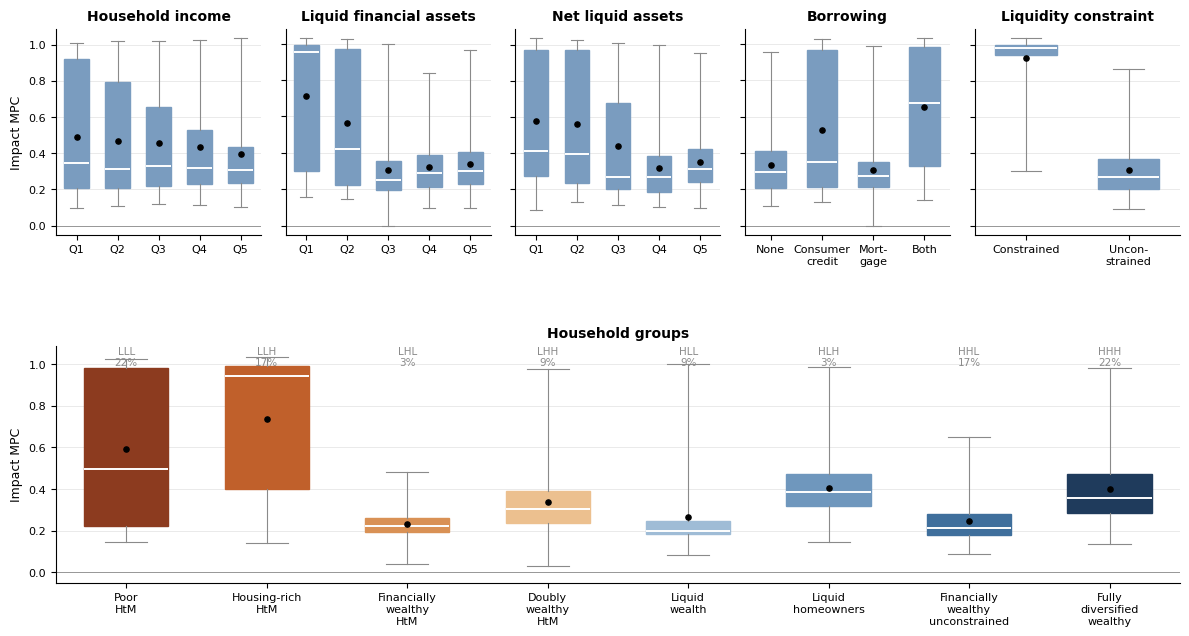

In [ ]:
top_row = [
    spec["income_paper_group"][:1] + ("Household income",) + (["Q1", "Q2", "Q3", "Q4", "Q5"],),
    spec["liquid_financial_assets_paper_group"][:1] + ("Liquid financial assets",) + (["Q1", "Q2", "Q3", "Q4", "Q5"],),
    spec["net_liquid_financial_assets_all_debt_paper_group"][:1]
    + ("Net liquid assets",)
    + (["Q1", "Q2", "Q3", "Q4", "Q5"],),
    ("borrowing", "Borrowing", ["No borrowing", "Consumer\ncredit", "Mortgage\nonly", "Both"]),
    ("constraint", "Liquidity constraint", ["Constrained", "Unconstrained"]),
]
GROUPS_TITLE = "Household groups"  # edit the bottom-row title here
# Bottom-row x labels by group code; "\n" breaks a line. Codes not listed keep the default.
GROUP_XLABELS = {
    "LLL": "Poor\nHtM",
    "LLH": "Housing-rich\nHtM",
    "LHL": "Financially\nwealthy\nHtM",
    "LHH": "Doubly\nwealthy\nHtM",
    "HLL": "Liquid\nwealth",
    "HLH": "Liquid\nhomeowners",
    "HHL": "Financially\nwealthy\nunconstrained",
    "HHH": "Fully\ndiversified\nwealthy",
}
# Display settings only: all retained observations still enter the means.
IMPACT_WHISKERS = (5, 95)  # Percentiles; (0, 100) shows min/max; 1.5 uses IQR whiskers.
IMPACT_SHOW_OUTLIERS = False  # Show individual observations beyond the whiskers.
IMPACT_YLIM = None  # Automatic limits; e.g. (-0.1, 1.3) to zoom in.

impact_means = mpc_impact_figure(
    mpc_panel,
    outcome=MPC_IMPACT,
    whis=IMPACT_WHISKERS,
    showfliers=IMPACT_SHOW_OUTLIERS,
    ylim=IMPACT_YLIM,
    group_specs=top_row,
    groups_title=GROUPS_TITLE,
    group_labels=GROUP_XLABELS,
    path=OUT / "paper_impact_mpc",
)
impact_means.to_csv(OUT / "paper_impact_mpc_group_means.csv", index=False)

## 2. Aggregate MPC table
Cash MPC, transfer-weighted (ΣΔC / Σtransfer) over **all** households in the filtered panel, for impact and cumulative horizons. No labour-income identification filter: cumulative MPCs include the general-equilibrium feedback of the transfer on labour income (net about +1% of the transfer). SE: standard deviation of per-seed MPCs / √seeds.

In [4]:
def weighted_mpc(panel, column):
    d = panel[np.isfinite(panel[column]) & np.isfinite(panel.real_shock_amount)]
    w = d.real_shock_amount
    per_seed = (d[column] * w).groupby(d.seed).sum() / w.groupby(d.seed).sum()
    return pd.Series(
        {
            "MPC": float((d[column] * w).sum() / w.sum()),
            "SE (seed)": float(per_seed.std(ddof=1) / np.sqrt(len(per_seed))),
            "Share < 0": float((d[column] < 0).mean()),
            "N": int(len(d)),
            "Seeds": int(d.seed.nunique()),
        }
    )


mpc_table = pd.DataFrame(
    {"Impact (transfer quarter)": weighted_mpc(mpc_panel, MPC_IMPACT)}
    | {f"Cumulative, {k}": weighted_mpc(mpc_panel, v) for k, v in MPC_CUMULATIVE.items()}
).T.astype({"N": int, "Seeds": int})
mpc_table.to_csv(OUT / "paper_mpc_table.csv")
mpc_table.style.format(
    {"MPC": "{:.3f}", "SE (seed)": "{:.4f}", "Share < 0": "{:.1%}", "N": "{:,.0f}", "Seeds": "{:.0f}"}
)

,MPC,SE (seed),Share < 0,N,Seeds
Impact (transfer quarter),0.449,0.0021,0.3%,"224,727",49
"Cumulative, 2 quarters",0.628,0.0023,3.2%,"224,727",49
"Cumulative, 3 quarters",0.872,0.0128,9.0%,"224,727",49
"Cumulative, 4 quarters",0.962,0.0185,14.1%,"224,727",49


In [5]:
latex = mpc_table[["MPC", "SE (seed)", "Share < 0", "N"]].to_latex(
    float_format="%.3f", header=["MPC", "SE (seed)", "Share $<0$", "$N$"], escape=False
)
(OUT / "paper_mpc_table.tex").write_text(latex)
print(latex)

\begin{tabular}{lrrrr}
\toprule
 & MPC & SE (seed) & Share $<0$ & $N$ \\
\midrule
Impact (transfer quarter) & 0.449 & 0.002 & 0.003 & 224727 \\
Cumulative, 2 quarters & 0.628 & 0.002 & 0.032 & 224727 \\
Cumulative, 3 quarters & 0.872 & 0.013 & 0.090 & 224727 \\
Cumulative, 4 quarters & 0.962 & 0.018 & 0.141 & 224727 \\
\bottomrule
\end{tabular}



### Cumulative MPC chart

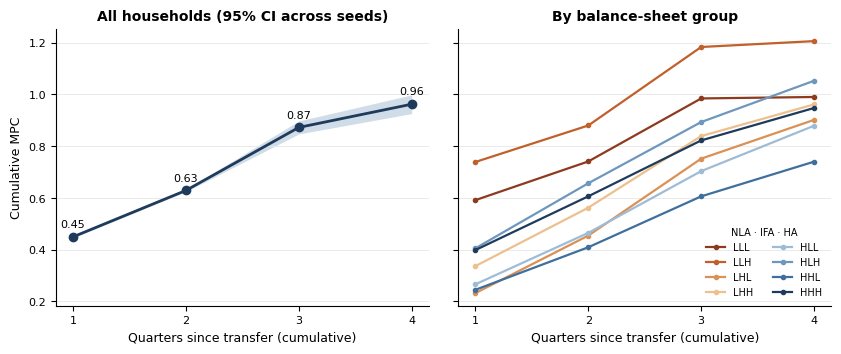

,LLL,LLH,LHL,LHH,HLL,HLH,HHL,HHH
1,0.591,0.739,0.232,0.336,0.266,0.405,0.245,0.398
2,0.741,0.880,0.454,0.562,0.464,0.656,0.409,0.606
3,0.984,1.183,0.751,0.839,0.703,0.893,0.606,0.822
4,0.990,1.206,0.901,0.961,0.879,1.053,0.740,0.947


In [6]:
horizons = {
    1: MPC_IMPACT,
    2: MPC_CUMULATIVE["2 quarters"],
    3: MPC_CUMULATIVE["3 quarters"],
    4: MPC_CUMULATIVE["4 quarters"],
}
aggregate = pd.DataFrame({q: weighted_mpc(mpc_panel, col)[["MPC", "SE (seed)"]] for q, col in horizons.items()}).T
aggregate.columns = ["MPC", "SE"]
by_group = pd.DataFrame(
    {
        code: {q: weighted_mpc(mpc_panel[mpc_panel.group_code == code], col)["MPC"] for q, col in horizons.items()}
        for code in GROUP_SHORT
    }
)
cumulative_mpc_figure(aggregate, by_group, path=OUT / "paper_cumulative_mpc")
by_group.round(3)

## 3. MPC by balance-sheet group (table)
All eight groups. KVW (2014) classes follow as a robustness check (monthly pay, one-month credit-limit proxy, DW = top two quintiles).

In [7]:
fmt = {"Population share": "{:.1%}", "MPC": "{:.3f}", "SE (seed)": "{:.4f}", "Share < 0": "{:.1%}", "N": "{:,.0f}"}


def group_table(panel, column, order):
    rows = {
        g: weighted_mpc(panel[panel[column] == g], MPC_IMPACT).to_dict()
        | {"Population share": float((panel[column] == g).mean())}
        for g in order
    }
    return pd.DataFrame(rows).T[["Population share", "MPC", "SE (seed)", "Share < 0", "N"]].astype({"N": int})


eight_table = group_table(mpc_panel, "group_code", list(GROUP_LABELS))
eight_table.insert(0, "Group", [GROUP_LABELS[c] for c in eight_table.index])
eight_table.to_csv(OUT / "paper_mpc_by_group8.csv")
(OUT / "paper_mpc_by_group8.tex").write_text(eight_table.to_latex(float_format="%.3f", escape=False))
eight_table.style.format(fmt)

,Group,Population share,MPC,SE (seed),Share < 0,N
LLL,Poor hand-to-mouth,21.7%,0.591,0.0029,0.1%,"48,695"
LLH,Housing-rich hand-to-mouth,16.6%,0.739,0.0035,0.2%,"37,238"
LHL,Financially wealthy hand-to-mouth,2.9%,0.232,0.0019,0.4%,"6,577"
LHH,Doubly wealthy hand-to-mouth,8.8%,0.336,0.0018,0.4%,"19,865"
HLL,Liquid-wealth households,8.9%,0.266,0.0018,0.4%,"19,983"
HLH,Liquid homeowners,2.9%,0.405,0.0023,0.2%,"6,459"
HHL,Financially wealthy unconstrained,16.5%,0.245,0.0019,0.4%,"37,122"
HHH,Fully diversified wealthy,21.7%,0.398,0.0022,0.4%,"48,788"


In [8]:
# 3c. Robustness: KVW classes (monthly pay, one-month credit-limit proxy, DW = top two quintiles).
mpc_panel["htm_class"] = classify_households(mpc_panel)
kvw_table = group_table(mpc_panel, "htm_class", HTM_CLASSES)
kvw_table.to_csv(OUT / "paper_mpc_by_kvw_class.csv")
kvw_table.style.format(fmt)

,Population share,MPC,SE (seed),Share < 0,N
P-HtM,16.9%,0.554,0.0031,0.1%,"37,936"
R-HtM,35.0%,0.573,0.0029,0.3%,"78,684"
DW,24.6%,0.377,0.0022,0.3%,"55,323"
Other,23.5%,0.265,0.0015,0.5%,"52,784"


## 4. Impulse responses
Mean across seeds (line) and 10th–90th percentile across seeds (band); deviation from the paired no-shock run. % for real GDP, real consumption and CPI; percentage points for unemployment and the policy rate (**annualised**: the model stores a quarterly rate). Horizon 0 = first quarter with the shock.

In [ ]:
PAPER_IRF_SHOCKS = {
    "policy_rate_100bp": "Monetary policy",
    "household_transfer_10pct": "One-off transfer",
    **JOB_LOSS_SHOCKS,
    # Excluded until fixed: income_tax_1pp (payroll wedge), gov_cons_5pct (rationing),
    # total_income_uncertainty_1pct: add after the rerun if clean.
}
PAPER_IRF_VARIABLES = {
    "real_gdp": "Real GDP, %",
    "real_cons": "Real consumption, %",
    "cpi": "CPI, %",
    "unemp": "Unemployment, pp",
    "policy_rate": "Policy rate, pp (annual)",
    "consumption_uncertainty_contribution": "Income uncertainty, %",
}
MAX_HORIZON = 16

irf_panel_path = IRF_DIR / "irf_panel.csv"
if not irf_panel_path.exists():
    raise FileNotFoundError(f"No saved IRFs at {irf_panel_path.resolve()}; check the experiment selectors above.")
irf_raw = pd.read_csv(irf_panel_path)
missing_shocks = set(PAPER_IRF_SHOCKS) - set(irf_raw.shock_name.unique())
if missing_shocks:
    raise ValueError(f"Selected dataset {IRF_DIR} is missing shocks: {sorted(missing_shocks)}")
irf_raw = irf_raw[irf_raw.shock_name.isin(PAPER_IRF_SHOCKS)]
irf = _prepare_irf_plot_panel(irf_raw)
irf = irf[irf.variable.isin(PAPER_IRF_VARIABLES) & (irf.horizon <= MAX_HORIZON)]
bands = (
    irf.groupby(["shock_name", "variable", "horizon"])["plot_value"]
    .agg(mean="mean", p10=lambda x: x.quantile(0.1), p90=lambda x: x.quantile(0.9), n="count")
    .reset_index()
)
bands.to_csv(OUT / "paper_irf_bands.csv", index=False)


# The model's policy rate is per quarter: annualise for display.
rate = bands.variable == "policy_rate"
bands.loc[rate, ["mean", "p10", "p90"]] *= 4
bands.to_csv(OUT / "paper_irf_bands.csv", index=False)
irf_figure(bands, shocks=PAPER_IRF_SHOCKS, variables=PAPER_IRF_VARIABLES, path=OUT / "paper_irf_macro")
print("seeds per cell:", bands.n.unique())

In [ ]:
# Peak responses for the text.
peaks = bands.loc[bands.groupby(["shock_name", "variable"])["mean"].apply(lambda s: s.abs().idxmax())]
peaks[["shock_name", "variable", "horizon", "mean", "p10", "p90"]].round(3)

### Job-loss shock: who pays for the lost wages?
Real changes (each run deflated by its own CPI) in household income components, in % of baseline household income, so the parts add up. In nominal terms transfers keep rising because they are indexed to prices and wages and the job-loss shock raises CPI. On impact the wage bill falls far less than employment (−0.7% vs −2.0%): remaining workers raise effort and are paid for it (ContractWageSetter, earnings = rate × effort).

In [ ]:
components = {
    "household_employee_income": "Employee income",
    "household_social_transfers": "Social transfers",
    "household_income": "Total household income",
}
if JOB_LOSS_SHOCK not in JOB_LOSS_SHOCKS:
    raise ValueError(f"Choose JOB_LOSS_SHOCK from {list(JOB_LOSS_SHOCKS)}")
raw_all = pd.read_csv(IRF_DIR / "irf_panel.csv")
job = raw_all[(raw_all.shock_name == JOB_LOSS_SHOCK) & (raw_all.horizon <= MAX_HORIZON)]
if not set(components).issubset(job.variable.unique()):
    raise ValueError(f"Missing income components for {JOB_LOSS_SHOCK} in {IRF_DIR}; check the selected saved run.")
else:
    # Real terms: deflate each run by its own CPI, in baseline prices of the same quarter.
    wide = job.pivot_table(index=["seed", "horizon"], columns="variable", values=["baseline", "shock"])
    deflator = wide["baseline", "cpi"] / wide["shock", "cpi"]
    base_income = wide["baseline", "household_income"]
    parts = (
        pd.DataFrame(
            {var: 100 * (wide["shock", var] * deflator - wide["baseline", var]) / base_income for var in components}
        )
        .groupby(level="horizon")
        .mean()
    )
    with plt.rc_context(paper_style):
        fig, ax = plt.subplots(figsize=(5.5, 3.3))
        colors = {
            "household_employee_income": "#c0602b",
            "household_social_transfers": "#6f97bd",
            "household_income": "#1f3b5c",
        }
        for var, label in components.items():
            ax.plot(
                parts.index, parts[var], label=label, color=colors[var], lw=2.2 if var == "household_income" else 1.6
            )
        ax.axhline(0, color="#8a8a8a", lw=0.6)
        ax.set_xlabel("Quarters")
        ax.set_ylabel("% of baseline household income (real)")
        ax.legend(fontsize=8)
        fig.savefig(OUT / "paper_job_loss_income.pdf")
        fig.savefig(OUT / "paper_job_loss_income.png", dpi=250)
        plt.show()
    parts.round(2)

## 5. Cumulative fiscal multiplier of the one-off transfer (provisional)
**Provisional:** reported to 16 quarters. The GDP multiplier is still rising at 24 quarters (deficit-financed transfer, no fiscal rule), to be resolved before final numbers.

$M_H = \sum_{h=0}^{H-1} \Delta Y^{real}_h \,/\, T$, per seed, then mean and SE across seeds.
- $T$: the transfer, measured as the h0 change in household income (labour incomes are identical across arms at h0).
- Real changes are in h0 prices: each arm is deflated by its own CPI relative to the baseline CPI at h0. No discounting.
- Consumption is in cash terms (goods including VAT, × 1.13), the same concept as the cash MPC.
- Uses the IRF run selected by `IRF_REGIME` in the setup cell.

In [ ]:
TRANSFER_SHOCK = "household_transfer_10pct"
MULTIPLIER_HORIZON = 16  # provisional: GDP multiplier has not converged by 24 quarters


def transfer_multipliers(irf_dir):
    """Per-quarter cumulative multipliers (mean and seed SE) for GDP and household consumption."""
    raw = pd.read_csv(irf_dir / "irf_panel.csv")
    raw = raw[raw.shock_name == TRANSFER_SHOCK]
    w = raw.pivot_table(index=["seed", "horizon"], columns="variable", values=["baseline", "shock", "delta"])
    cpi_b, cpi_s = w["baseline", "cpi"], w["shock", "cpi"]
    cpi_b0 = cpi_b.groupby(level=0).transform("first")
    transfer = w["delta", "household_income"].xs(0, level=1)
    out = {}
    for var, key in [("gdp_output", "gdp"), ("household_consumption", "cons")]:
        real = (w["shock", var] / (cpi_s / cpi_b0) - w["baseline", var] / (cpi_b / cpi_b0)).unstack()
        cum = real.cumsum(axis=1).div(transfer, axis=0).iloc[:, :MULTIPLIER_HORIZON]
        if key == "cons":  # IRF consumption is goods excluding VAT: express in cash terms, like the MPC
            cum = cum * (1 + VAT_RATE)
        out[key] = cum.mean()
        out[f"{key}_se"] = cum.std(ddof=1) / np.sqrt(len(cum))
    curves = pd.DataFrame(out)
    curves.index = curves.index + 1  # quarters elapsed, including the transfer quarter
    share = (transfer / w["baseline", "household_income"].xs(0, level=1)).mean()
    return curves, share, len(transfer)


curves, share, n_seeds = transfer_multipliers(IRF_DIR)
print(f"IRF run: {IRF_REGIME}; transfer = {share:.1%} of quarterly household income; {n_seeds} seeds")
MULTIPLIER_TITLES = ("Real GDP", "Real household consumption")  # edit panel titles here
multiplier_figure(
    {IRF_REGIME: curves}, path=OUT / "paper_transfer_multiplier", annotate=(4, 8, 16), titles=MULTIPLIER_TITLES
)
multiplier = curves.loc[[1, 4, 8, 12, 16]].rename(
    columns={"gdp": "GDP", "gdp_se": "GDP SE", "cons": "Consumption", "cons_se": "Consumption SE"}
)
multiplier.index.name = "Quarters"
multiplier.to_csv(OUT / "paper_transfer_multiplier.csv")
(OUT / "paper_transfer_multiplier.tex").write_text(multiplier.to_latex(float_format="%.2f"))
multiplier.round(3)

In [ ]:
# Heterogeneous households in a behavioural, balance-sheet driven, agent-based model for consumption.